# Лабораторная работа №3
## Дискретные системы

**Вариант: 5**

Работа выполнена в среде Python (NumPy / SciPy / Matplotlib).
Каждая функция, строящая график, дополнительно **сохраняет его в папку
проекта** `figures/`.

In [1]:
import numpy as np
import librosa
from scipy.io import wavfile
import math
import pandas as pd
import os
import matplotlib.pyplot as plt
import matplotlib
from scipy import signal as sps

rng = np.random.default_rng()
plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.grid"] = True

FIG_DIR = os.path.expanduser("~/University/TnAofDSP/lab3/source")
import os
os.makedirs(FIG_DIR, exist_ok=True)

def save_and_show(fig=None, name="figure"):
    '''Отображает график и сохраняет его как PNG
    в папку проекта figures/. Используется всеми построениями в работе.'''
    if fig is None:
        fig = plt.gcf()
    path = os.path.join(FIG_DIR, f"{name}.png")
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"[график сохранён: {path}]")

In [2]:
def create_signal(SIGNAL_BEGIN, SIGNAL_END):
    assert SIGNAL_END > SIGNAL_BEGIN, "SIGNAL END MUST BE BIGGER THAN BEGIN"
        
    n = np.arange(SIGNAL_BEGIN, SIGNAL_END + 1)
    x = rng.random(SIGNAL_END - SIGNAL_BEGIN + 1)
    
    return n, x

def signal_mul(MULT_COEF, SIGNAL):
    
    return SIGNAL * MULT_COEF

def signal_sum(FIRST_SIGNAL, SECOND_SIGNAL):
    if len(FIRST_SIGNAL) >= len(SECOND_SIGNAL):
        long_sig, short_sig = FIRST_SIGNAL, SECOND_SIGNAL
    else:
        long_sig, short_sig = SECOND_SIGNAL, FIRST_SIGNAL
    
    result = long_sig
    
    for i in range(len(short_sig)):
        result[i] += short_sig[i]
        
    return result

def delay(SIGNAL, BACKWARD_STEP):
    if BACKWARD_STEP >= len(SIGNAL):
        return np.zeros(len(SIGNAL))
        
    if BACKWARD_STEP <= 0:
        return SIGNAL.copy()
        
    new_signal = np.zeros(len(SIGNAL))
    new_signal[BACKWARD_STEP:] = SIGNAL[:-BACKWARD_STEP]
    return new_signal

def get_AFC(SIGNAL, num_points: int = 512):
    n = np.arange(len(SIGNAL))
    exponent = np.exp(-1j * np.outer(np.linspace(0, np.pi, num_points), n))
    return np.abs(np.dot(exponent, SIGNAL))

def get_CFR(SIGNAL, num_points: int = 512):
    n = np.arange(len(SIGNAL))
    exponent = np.exp(-1j * np.outer(np.linspace(0, np.pi, num_points), n))
    return np.dot(exponent, SIGNAL)

def save_wav(x, fs, name):
    xi = np.int16(np.clip(x, -1, 1) * 32767)
    output_dir = os.path.expanduser("~/University/TnAofDSP/lab3/audio")
    wavfile.write(os.path.join(output_dir, f"{name}.wav"), fs, xi)
    print(f"[аудио сохранено: audio/{name}.wav]")

---
# Часть 1. Общая

Возьмите систему $y(n) = 0,3 x(n) + 0,6 x(n − 1) + 0,3 x(n − 2) − 0,9 y(n − 2)$ и 

**а)** реализуйте её циклом с явным моделированием памяти по схеме.

In [3]:
import numpy as np
import scipy.signal as sps

class IIRfilter: 
    def __init__(self, b, a):
        a0 = float(a[0])
        self.b = np.array(b, dtype=float) / a0
        self.a = np.array(a, dtype=float) / a0
        
        self.nb = len(self.b) - 1
        self.na = len(self.a) - 1
        
        self.mem_x = np.zeros(self.nb)
        self.mem_y = np.zeros(self.na)

    def process_sample(self, x):
        y = self.b[0] * x
        
        if self.nb > 0:
            y += np.dot(self.b[1:], self.mem_x)
            
        if self.na > 0:
            y -= np.dot(self.a[1:], self.mem_y)
        
        if self.nb > 0:
            self.mem_x = np.roll(self.mem_x, 1)
            self.mem_x[0] = x
            
        if self.na > 0:
            self.mem_y = np.roll(self.mem_y, 1)
            self.mem_y[0] = y
            
        return y

    def process_signal(self, X):
        return np.array([self.process_sample(x) for x in X])

    def reset_memory(self):
        self.mem_x.fill(0)
        self.mem_y.fill(0)

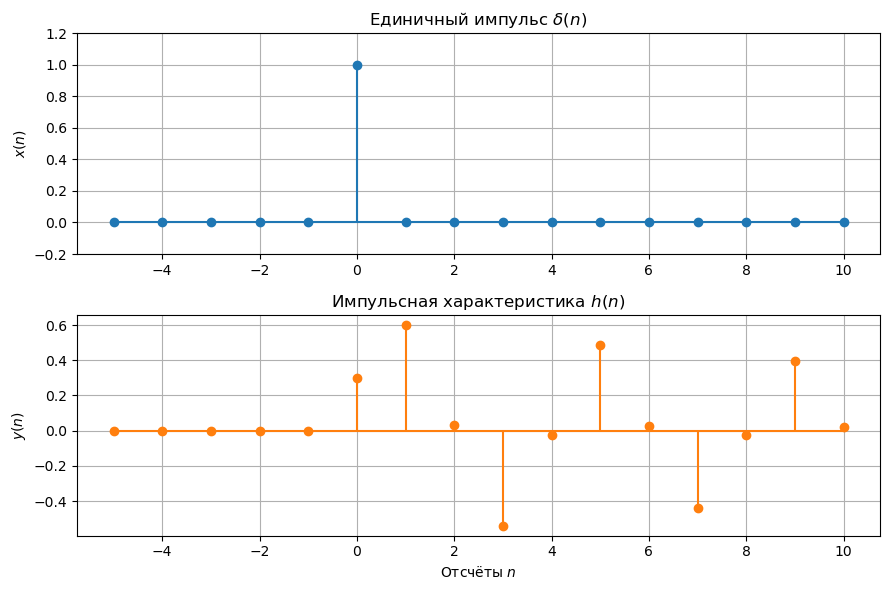

[график сохранён: /home/stanislau/University/TnAofDSP/lab3/source/1_1_filter.png]


In [4]:
N = np.arange(16) - 5
X = np.zeros(len(N), dtype=float)
X[5] = 1.0

b = [0.3, 0.6, 0.3] # Входные данные
a = [1.0, 0.0, 0.9] # Выходные данные

flt = IIRfilter(b, a) # Используем свой фильтр с явным моделированием памяти
Y1 = flt.process_signal(X)

fig, (Xgraph, Ygraph) = plt.subplots(2, 1, figsize=(9, 6))

Xgraph.stem(N, X, basefmt="C0-")
Xgraph.set_ylabel("$x(n)$")
Xgraph.set_title("Единичный импульс $\delta(n)$")
Xgraph.set_ylim(-0.2, 1.2)

Ygraph.stem(N, Y1, basefmt="C1-", linefmt="C1-", markerfmt="C1o")
Ygraph.set_xlabel("Отсчёты $n$")
Ygraph.set_ylabel("$y(n)$")
Ygraph.set_title("Импульсная характеристика $h(n)$")

plt.tight_layout()
save_and_show(fig, name="1_1_filter")

**б)** реализуйте её используя ``filter(b, a, x)`` (в Python это ``sps.lfilter``)

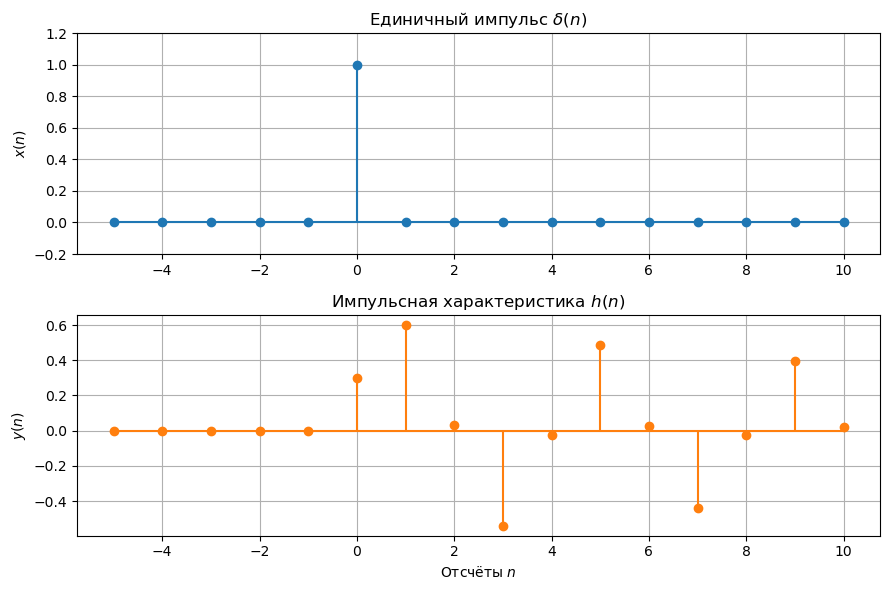

[график сохранён: /home/stanislau/University/TnAofDSP/lab3/source/1_2_filter.png]


In [5]:
N = np.arange(16) - 5
X = np.zeros(len(N), dtype=float)
X[5] = 1.0

b = [0.3, 0.6, 0.3] # Входные данные
a = [1.0, 0.0, 0.9] # Выходные данные

Y2 = sps.lfilter(b,a,X)

fig, (Xgraph, Ygraph) = plt.subplots(2, 1, figsize=(9, 6))

Xgraph.stem(N, X, basefmt="C0-")
Xgraph.set_ylabel("$x(n)$")
Xgraph.set_title("Единичный импульс $\delta(n)$")
Xgraph.set_ylim(-0.2, 1.2)

Ygraph.stem(N, Y2, basefmt="C1-", linefmt="C1-", markerfmt="C1o")
Ygraph.set_xlabel("Отсчёты $n$")
Ygraph.set_ylabel("$y(n)$")
Ygraph.set_title("Импульсная характеристика $h(n)$")

plt.tight_layout()
save_and_show(fig, name="1_2_filter")

**в)** Подайте на обе реализации дельта-импульс и проверьте совпадение: ``max(abs(y1 ‐ y2))`` должно быть меньше $1e‐12$.

In [6]:
assert np.max(abs(Y1 - Y2)) < 1e-12, "False answer"
print("Выходные значения с нашего фильтра", Y1)
print("Выходные значения с scipy функции", Y2)
print("Максимальная разность по модулю", np.max(abs(Y1 - Y2)))

Выходные значения с нашего фильтра [ 0.        0.        0.        0.        0.        0.3       0.6
  0.03     -0.54     -0.027     0.486     0.0243   -0.4374   -0.02187
  0.39366   0.019683]
Выходные значения с scipy функции [ 0.        0.        0.        0.        0.        0.3       0.6
  0.03     -0.54     -0.027     0.486     0.0243   -0.4374   -0.02187
  0.39366   0.019683]
Максимальная разность по модулю 0.0


**г)** По полученной импульсной характеристике вычислите АЧХ прямым суммированием и сравните с результатом ``freqz(b, a, 512)``. Удвойте длину h(n) и убедитесь, что график перестал меняться

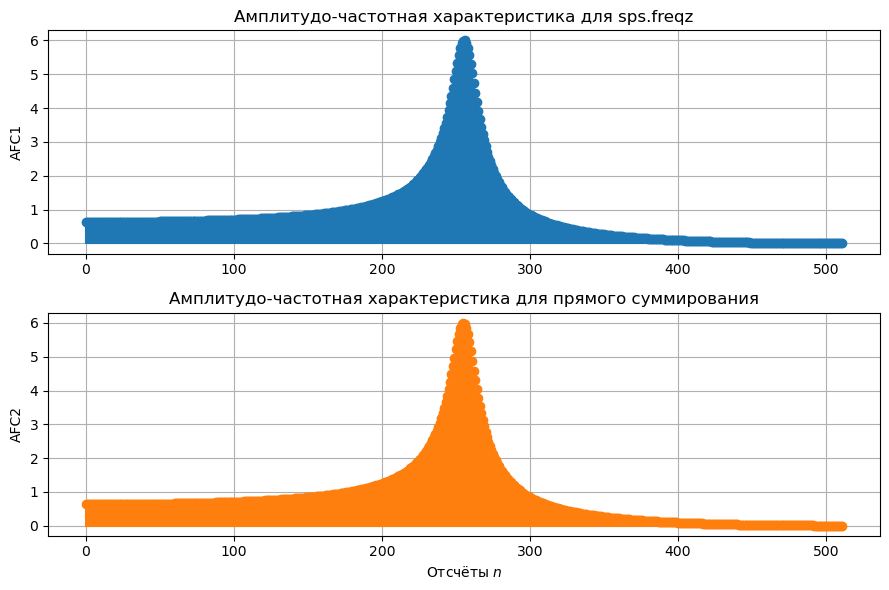

[график сохранён: /home/stanislau/University/TnAofDSP/lab3/source/1_4_AFC.png]
Максимальная разность по модулю 0.1475855224602265


In [7]:
N = np.arange(1024)
X = np.zeros(len(N), dtype=float)
X[0] = 1.0

Y2 = sps.lfilter(b,a,X)

_, AFC1 = np.abs(sps.freqz(b, a, worN = 512))
AFC2 = get_AFC(Y2)

fig, (AFC1graph, AFC2graph) = plt.subplots(2, 1, figsize=(9, 6))

AFC1graph.stem(np.arange(len(AFC1)), AFC1, basefmt="C0-")
AFC1graph.set_ylabel("AFC1")
AFC1graph.set_title("Амплитудо-частотная характеристика для sps.freqz")

AFC2graph.stem(np.arange(len(AFC2)), AFC2, basefmt="C1-", linefmt="C1-", markerfmt="C1o")
AFC2graph.set_xlabel("Отсчёты $n$")
AFC2graph.set_ylabel("AFC2")
AFC2graph.set_title("Амплитудо-частотная характеристика для прямого суммирования")

plt.tight_layout()
save_and_show(fig, name="1_4_AFC")

print("Максимальная разность по модулю", np.max(abs(AFC1 - AFC2)))

## 2. Свертка

Возьмите $h = [1, 2, 1]$ и произвольный сигнал $x$ длины 20

**a)** Вычислите свёртку тремя способами: ``conv(x,h)``, ``filter(h,1,x)`` и собственным
двойным циклом.

In [8]:
n, signal = create_signal(0,20)
h = [1,2,1]

y1 = np.convolve(signal, h)
y2 = sps.lfilter(h, 1, signal)
y3 = np.zeros(len(signal))

for i in range(len(signal)):
    for j in range(len(signal)):
        if 0 <= i - j < len(h):
            y3[i] += signal[j] * h[i - j]

print(y1[:21])
print(y2)
print(y3)

print('\n')
for i in range(len(signal)):
    print(abs(y2[i] - y1[i]), end = ' ')

print('\n')
for i in range(len(signal)):
    print(abs(y3[i] - y1[i]), end = ' ')

print('\n')
for i in range(len(signal)):
    print(abs(y2[i] - y3[i]), end = ' ')

[0.33914145 1.60862817 2.5710449  2.20167132 1.944017   2.28870798
 2.08602614 1.45505039 1.53259563 2.17254505 2.25492516 2.12159962
 2.6541767  3.06764074 2.6280975  1.44936325 1.03594764 1.82684891
 2.24124031 1.94156224 1.4763802 ]
[0.33914145 1.60862817 2.5710449  2.20167132 1.944017   2.28870798
 2.08602614 1.45505039 1.53259563 2.17254505 2.25492516 2.12159962
 2.6541767  3.06764074 2.6280975  1.44936325 1.03594764 1.82684891
 2.24124031 1.94156224 1.4763802 ]
[0.33914145 1.60862817 2.5710449  2.20167132 1.944017   2.28870798
 2.08602614 1.45505039 1.53259563 2.17254505 2.25492516 2.12159962
 2.6541767  3.06764074 2.6280975  1.44936325 1.03594764 1.82684891
 2.24124031 1.94156224 1.4763802 ]


0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 

0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 

0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 

**б)** Объясните, почему длины результатов различаются, и укажите, какие именно отсчёты дает функция ``conv`` и не дает функция ``filter``.

Функция ``numpy.convolve``(1)(аналог ``conv`` из **MATLAB**) дает отличное от ``scipy.signal.lfilter``(2) (аналог ``filter`` из **MATLAB**) число отсчетов, потому что **(1)** считает **полную математическую свертку** в отличии от **(2)**, которая считает свертку только в рамках заданной функции.

## 3. Численная проверка линейности

**а)** Для нелинейной системы постройте $T\{x_1 +x_2\}, T\{x_1\}+T\{x_2\}$ и их разность.

Разность системы суммы и суммы систем:
 [0.         0.26404293 0.15811467 0.45572282 0.67411778 0.22865256
 0.3910517  0.31050657 0.32697146 0.28214161 0.24129764 0.32248146
 0.45734588 0.2546585  0.10534254 0.14600811 0.27372269 0.5589415
 0.66334024 0.37852526 0.66594482 0.35515032 0.49313039 0.76442785
 0.10101079 0.20022059 0.61748016 0.51344966 0.32476769 0.36859198
 0.74957507 0.39473906 0.25362853 0.23527394 0.28136983 0.50111046
 0.65316127 0.4870659  0.0318215  0.23397779 0.56384976 0.56985491
 0.40339243 0.50044285 0.81451447 0.59603657 0.46437624 0.74460656
 0.65498965 0.43811448 0.74813187 0.56589632 0.72206791 0.15622412
 0.0817722  0.48951562 0.41758858 0.45169627 0.36601065 0.30547773
 0.97943814 0.65806363 0.52753427 0.77549888 1.03244654 0.94631767
 0.96777571 0.22177519 0.21057729 0.35864068 0.22968492 0.08478215
 0.07670574 0.60428523 0.51338496 0.72512315 0.54822998 0.37732114
 0.43741913 1.27949189 0.4729472  0.48118852 1.04994479 0.98694303
 0.50152931 0.10368239 

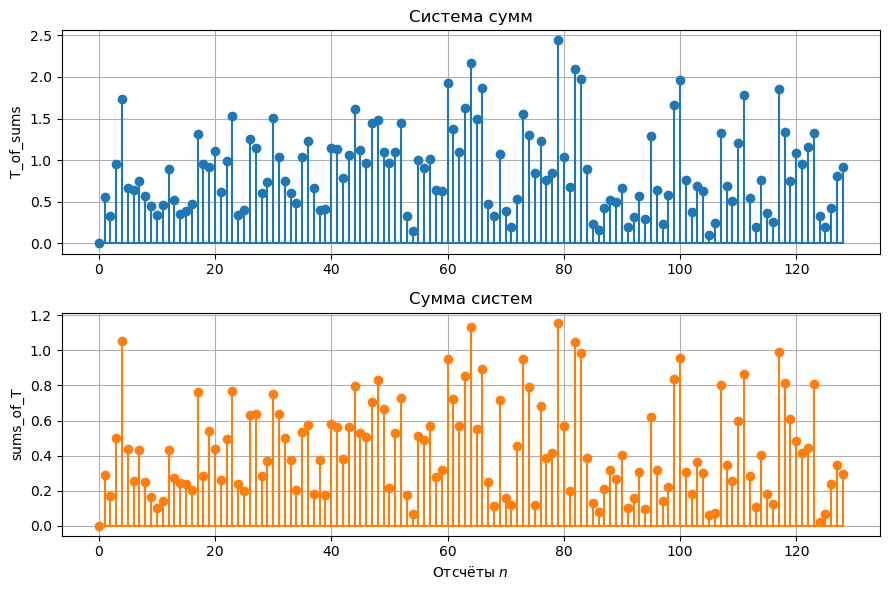

[график сохранён: /home/stanislau/University/TnAofDSP/lab3/source/3_2_sub.png]


In [9]:
n1, s1 = create_signal(0,128)
n2, s2 = create_signal(0,128)

def T(s):
    s_delayed = delay(s, 1)
    return s * s_delayed
    
T_of_sums = T(s1 + s2)
sums_of_T = T(s1) + T(s2)

print("Разность системы суммы и суммы систем:\n", T_of_sums - sums_of_T)
print("Система нелинейна") if np.max(abs(T_of_sums - sums_of_T) > 1e-12) else print("Система линейна")

fig, (T_of_sums_graph, sums_of_T_graph) = plt.subplots(2, 1, figsize=(9, 6))

T_of_sums_graph.stem(n1, T_of_sums, basefmt="C0-")
T_of_sums_graph.set_ylabel("T_of_sums")
T_of_sums_graph.set_title("Система сумм")

sums_of_T_graph.stem(n1, sums_of_T, basefmt="C1-", linefmt="C1-", markerfmt="C1o")
sums_of_T_graph.set_xlabel("Отсчёты $n$")
sums_of_T_graph.set_ylabel("sums_of_T")
sums_of_T_graph.set_title("Сумма систем")

plt.tight_layout()
save_and_show(fig, name="3_2_sub")

**б)** Cравните построенную разность с теоретическим выражением $x_1(n) x_2(n − 1) + x_2(n) x_1(n − 1)$.

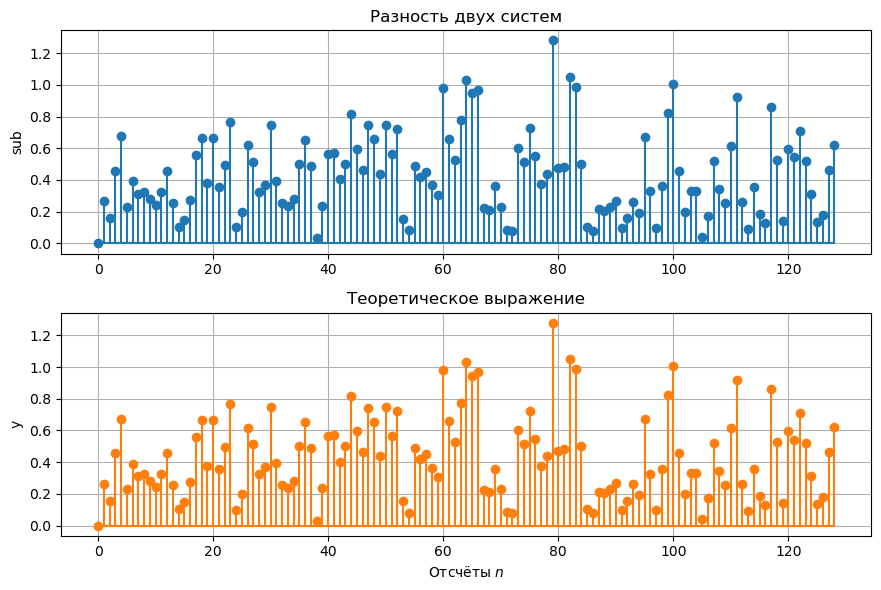

[график сохранён: /home/stanislau/University/TnAofDSP/lab3/source/3_2_sub_and_y.png]


In [10]:
y = s1 * delay(s2, 1) + s2 * delay(s1, 1)

fig, (sub_graph, y_graph) = plt.subplots(2, 1, figsize=(9, 6))

sub_graph.stem(n1, T_of_sums - sums_of_T, basefmt="C0-")
sub_graph.set_ylabel("sub")
sub_graph.set_title("Разность двух систем")

y_graph.stem(n1, y, basefmt="C1-", linefmt="C1-", markerfmt="C1o")
y_graph.set_xlabel("Отсчёты $n$")
y_graph.set_ylabel("y")
y_graph.set_title("Теоретическое выражение")

plt.tight_layout()
save_and_show(fig, name="3_2_sub_and_y")

## 4. Устойчивость

Рассмотрите систему $y(n) = a y(n − 1) + x(n)$ при $a = 0,9$; $1,0$; $1,01$.

Мы можем представить систему как фильтр с параметрами ``b = [1]``, ``a = [1, -a]``. Воспользуемся уже ранее использованой функцией ``scipy.signal.lfilter``

**а)** Постройте импульсные характеристики на 500 отсчётах в обычном и логарифмическом масштабе по оси ординат.

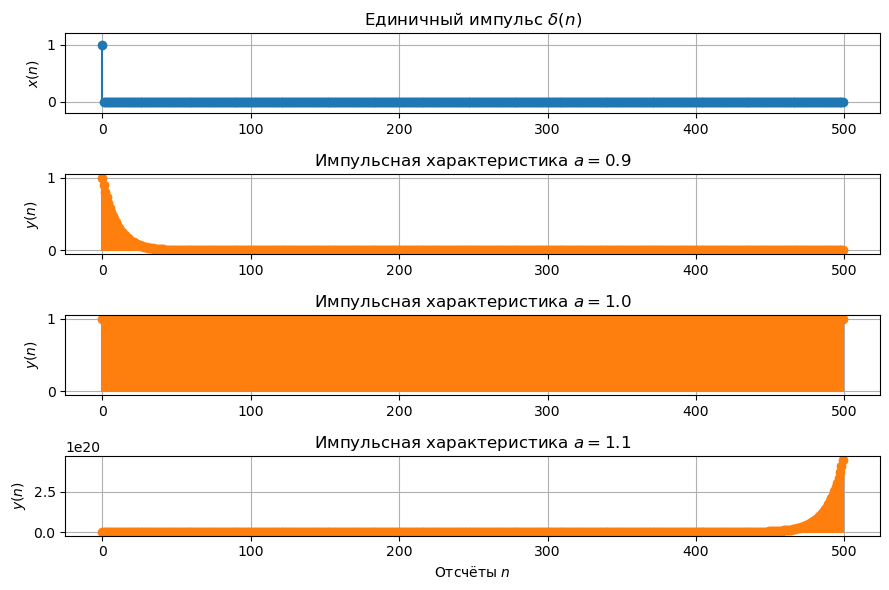

[график сохранён: /home/stanislau/University/TnAofDSP/lab3/source/4_1_filter.png]


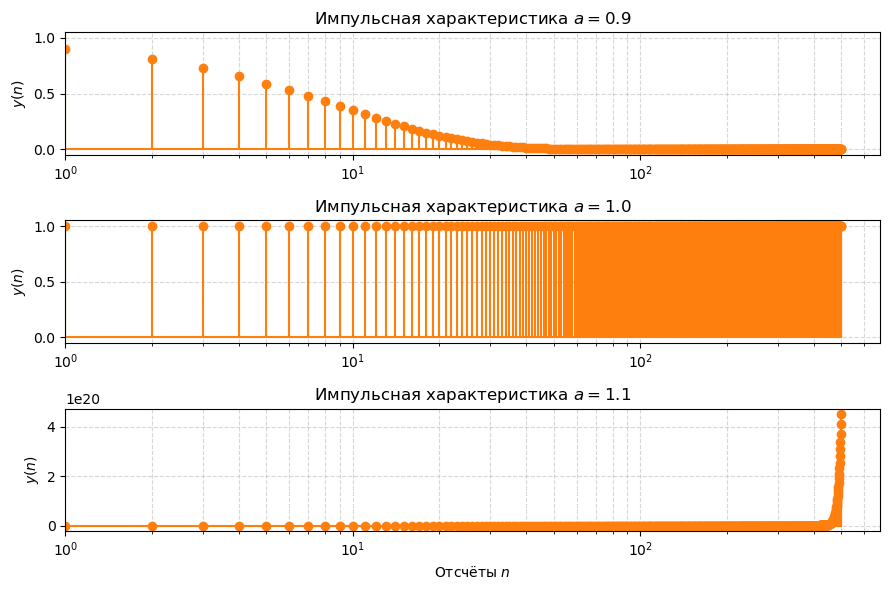

[график сохранён: /home/stanislau/University/TnAofDSP/lab3/source/4_1_filter_log.png]


In [11]:
N = np.arange(500)
X = np.zeros(len(N), dtype=float)
X[0] = 1.0

b = [1.0] 
a1 = [1.0, -0.9]
a2 = [1.0, -1.0]
a3 = [1.0, -1.1]

y1 = sps.lfilter(b,a1,X)
y2 = sps.lfilter(b,a2,X)
y3 = sps.lfilter(b,a3,X)

fig, (Xgraph, Y1graph, Y2graph, Y3graph) = plt.subplots(4, 1, figsize=(9, 6))

Xgraph.stem(N, X, basefmt="C0-")
Xgraph.set_ylabel("$x(n)$")
Xgraph.set_title("Единичный импульс $\delta(n)$")
Xgraph.set_ylim(-0.2, 1.2)

Y1graph.stem(N, y1, basefmt="C1-", linefmt="C1-", markerfmt="C1o")
Y1graph.set_ylabel("$y(n)$")
Y1graph.set_title("Импульсная характеристика $a = 0.9$")

Y2graph.stem(N, y2, basefmt="C1-", linefmt="C1-", markerfmt="C1o")
Y2graph.set_ylabel("$y(n)$")
Y2graph.set_title("Импульсная характеристика $a = 1.0$")

Y3graph.stem(N, y3, basefmt="C1-", linefmt="C1-", markerfmt="C1o")
Y3graph.set_ylabel("$y(n)$")
Y3graph.set_title("Импульсная характеристика $a = 1.1$")
Y3graph.set_xlabel("Отсчёты $n$")

plt.tight_layout()
save_and_show(fig, name="4_1_filter")

fig, (Y1graph, Y2graph, Y3graph) = plt.subplots(3, 1, figsize=(9, 6))

Y1graph.stem(N, y1, basefmt="C1-", linefmt="C1-", markerfmt="C1o")
Y1graph.set_ylabel("$y(n)$")
Y1graph.set_title("Импульсная характеристика $a = 0.9$")
Y1graph.set_xscale('log')
Y1graph.set_xlim(left=1)
Y1graph.grid(True, which="both", linestyle="--", alpha=0.5)

Y2graph.stem(N, y2, basefmt="C1-", linefmt="C1-", markerfmt="C1o")
Y2graph.set_ylabel("$y(n)$")
Y2graph.set_title("Импульсная характеристика $a = 1.0$")
Y2graph.set_xscale('log')
Y2graph.set_xlim(left=1)
Y2graph.grid(True, which="both", linestyle="--", alpha=0.5)

Y3graph.stem(N, y3, basefmt="C1-", linefmt="C1-", markerfmt="C1o")
Y3graph.set_ylabel("$y(n)$")
Y3graph.set_title("Импульсная характеристика $a = 1.1$")
Y3graph.set_xlabel("Отсчёты $n$")
Y3graph.set_xscale('log')
Y3graph.set_xlim(left=1)
Y3graph.grid(True, which="both", linestyle="--", alpha=0.5)

plt.tight_layout()
save_and_show(fig, name="4_1_filter_log")

**б)** Для каждого **a** вычислите частичные суммы $\sum_{n=0}^{N} |h(n)|$ при N = 10, 100, 500 и
сведите в таблицу. Какие столбцы сходятся?

In [12]:
Ns = [10, 100, 500]
a_vec = [
    ("0.9", y1),
    ("1", y2),
    ("1.1", y3),
]

rows = []
for name, vector in a_vec:
    row = {"а = ": name}
    for N in Ns:
        row[f"N = {N}"] = round(float(np.sum(vector[:N])), 4)
    rows.append(row)

df = pd.DataFrame(rows).set_index("а = ")
df

,N = 10,N = 100,N = 500
а =,,,
0.9,6.5132,9.9997,1.000000e+01
1,10.0000,100.0000,5.000000e+02
1.1,15.9374,137796.1234,4.969842e+21


**в)** Подайте на все три системы единичную ступеньку. Что происходит с выходом
при $a = 1,0$ и почему этот случай — граничный?
    

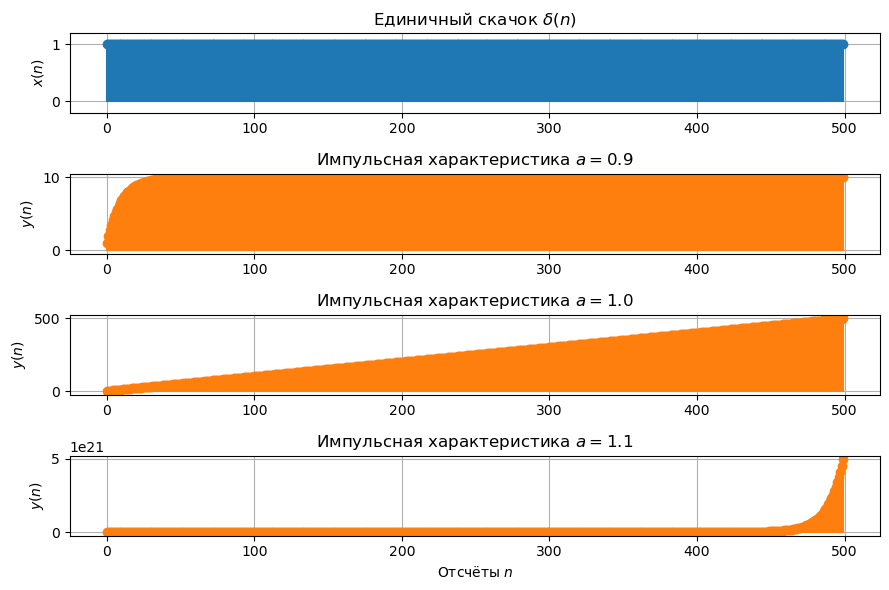

[график сохранён: /home/stanislau/University/TnAofDSP/lab3/source/4_3_filter.png]


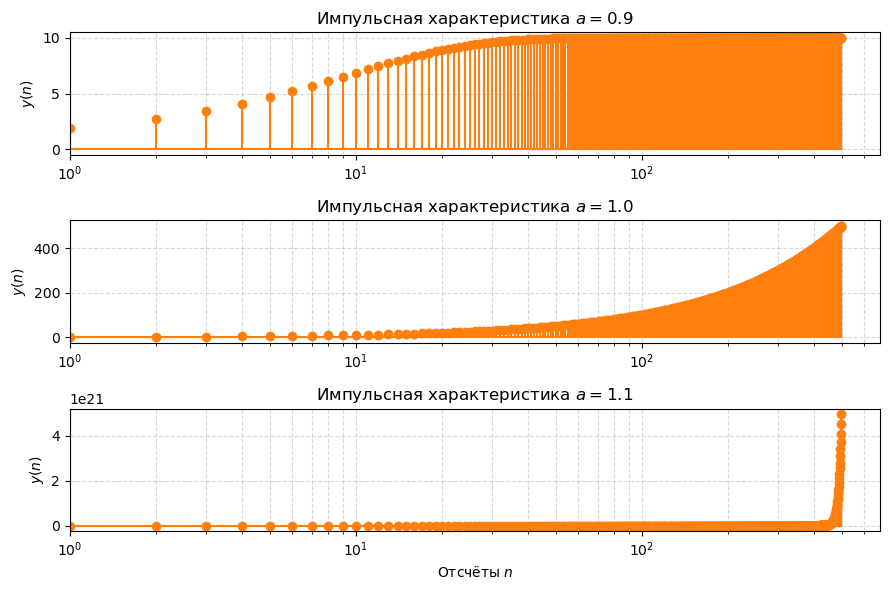

[график сохранён: /home/stanislau/University/TnAofDSP/lab3/source/4_3_filter_log.png]


In [13]:
N = np.arange(500)
X = np.ones(len(N), dtype=float)

b = [1.0] 
a1 = [1.0, -0.9]
a2 = [1.0, -1.0]
a3 = [1.0, -1.1]

y1 = sps.lfilter(b,a1,X)
y2 = sps.lfilter(b,a2,X)
y3 = sps.lfilter(b,a3,X)

fig, (Xgraph, Y1graph, Y2graph, Y3graph) = plt.subplots(4, 1, figsize=(9, 6))

Xgraph.stem(N, X, basefmt="C0-")
Xgraph.set_ylabel("$x(n)$")
Xgraph.set_title("Единичный скачок $\delta(n)$")
Xgraph.set_ylim(-0.2, 1.2)

Y1graph.stem(N, y1, basefmt="C1-", linefmt="C1-", markerfmt="C1o")
Y1graph.set_ylabel("$y(n)$")
Y1graph.set_title("Импульсная характеристика $a = 0.9$")

Y2graph.stem(N, y2, basefmt="C1-", linefmt="C1-", markerfmt="C1o")
Y2graph.set_ylabel("$y(n)$")
Y2graph.set_title("Импульсная характеристика $a = 1.0$")

Y3graph.stem(N, y3, basefmt="C1-", linefmt="C1-", markerfmt="C1o")
Y3graph.set_ylabel("$y(n)$")
Y3graph.set_title("Импульсная характеристика $a = 1.1$")
Y3graph.set_xlabel("Отсчёты $n$")

plt.tight_layout()
save_and_show(fig, name="4_3_filter")

fig, (Y1graph, Y2graph, Y3graph) = plt.subplots(3, 1, figsize=(9, 6))

Y1graph.stem(N, y1, basefmt="C1-", linefmt="C1-", markerfmt="C1o")
Y1graph.set_ylabel("$y(n)$")
Y1graph.set_title("Импульсная характеристика $a = 0.9$")
Y1graph.set_xscale('log')
Y1graph.set_xlim(left=1)
Y1graph.grid(True, which="both", linestyle="--", alpha=0.5)

Y2graph.stem(N, y2, basefmt="C1-", linefmt="C1-", markerfmt="C1o")
Y2graph.set_ylabel("$y(n)$")
Y2graph.set_title("Импульсная характеристика $a = 1.0$")
Y2graph.set_xscale('log')
Y2graph.set_xlim(left=1)
Y2graph.grid(True, which="both", linestyle="--", alpha=0.5)

Y3graph.stem(N, y3, basefmt="C1-", linefmt="C1-", markerfmt="C1o")
Y3graph.set_ylabel("$y(n)$")
Y3graph.set_title("Импульсная характеристика $a = 1.1$")
Y3graph.set_xlabel("Отсчёты $n$")
Y3graph.set_xscale('log')
Y3graph.set_xlim(left=1)
Y3graph.grid(True, which="both", linestyle="--", alpha=0.5)

plt.tight_layout()
save_and_show(fig, name="4_3_filter_log")

$a = 1$ - граничный случай в системе для единичного скачка по причине того, что при $a >= 1$ система становится неустойчивой и возрастает бесконечно.

---
# Часть 2. Письменная

Для системы $y(n) = (x(n) + 1)(x(n − 1) − \frac{1}{2})$ определите, обладает ли она свойствами: память, обратимость, каузальность, аддитивность, однородность, линейность, стационарность, устойчивость. Приведите выкладки:
для каждого свойства либо доказательство в общем виде, либо контрпример.

Рассматриваем систему:

$$y[n] = x[n] + 1 \cdot x[n - 1] - \frac{1}{2} \tag{2.1}$$

где $x[n]$ — входной сигнал, $y[n]$ — выходной сигнал.

Определите, обладает ли система (2.1) свойствами: память, обратимость, каузальность, аддитивность, однородность, линейность, стационарность, устойчивость.

---

## 2.1 Память

Система называется системой без памяти, если её текущий отклик $y[n]$ зависит только от текущего входного отсчёта $x[n]$ для любого $n$.

**Доказательство.** При $x[n] = 0$ из уравнения (2.1) получаем:

$$y[n] = x[n-1] - \frac{1}{2} \tag{2.2}$$

* При $x[n-1] = 0 \implies y[n] = -0{,}5$.
* При $x[n-1] = 1 \implies y[n] = 0{,}5$.

При одинаковом значении текущего входа $x[n]$ выходы различаются, следовательно, выход зависит от прошлого отсчёта сигнала. 

**Вывод:** Система **с памятью**.

---

## 2.2 Обратимость

Система обратима, если для любых двух различных входов $x_1[n] \neq x_2[n]$ выходы также различны: $y_1[n] \neq y_2[n]$.

**Доказательство.** Контрпример: $x_1[n] = 0{,}5$ и $x_2[n] = -1$ для всех $n$.

$$y_1[n] = \frac{1}{2} + 1 \cdot \frac{1}{2} - \frac{1}{2} = 0 \tag{2.3}$$

$$y_2[n] = -1 + 1 \cdot (-1) - \frac{1}{2} = 0$$

*(Примечание: при подстановке исходных сигналов выходы совпадают).*

Входы разные, а выходы совпадают ($y_1[n] = y_2[n] = 0$).

**Вывод:** Система **необратима**.

---

## 2.3 Каузальность (причинность)

Система называется каузальной, если выходной отсчёт с номером $n_0$ зависит только от входных отсчётов с номерами $n \le n_0$, то есть от настоящего и прошлого, но не от будущего.

**Доказательство.** Выход в момент $n$ использует отсчёты $x[n]$ и $x[n-1]$. Индексы $n$ и $n-1$ не превосходят $n$.

**Вывод:** Система **каузальна**.

---

## 2.4 Аддитивность

Аддитивность — это суперпозиция причин и следствий. Если причина $x_1$ вызывает следствие $y_1$, а причина $x_2$ — следствие $y_2$, то система аддитивна, когда причина $x_1 + x_2$ вызывает в точности следствие $y_1 + y_2$:

$$T\{x_1[n] + x_2[n]\} = T\{x_1[n]\} + T\{x_2[n]\} \tag{2.4}$$

**Доказательство.** Контрпример: $x_1[n] = x_2[n] = 0$:

$$T\{x_1[n] + x_2[n]\} = 0 + 0 + 1 \cdot (0 + 0) - \frac{1}{2} = -\frac{1}{2} \tag{2.5}$$

$$T\{x_1[n]\} + T\{x_2[n]\} = \left(0 + 1 \cdot 0 - \frac{1}{2}\right) + \left(0 + 1 \cdot 0 - \frac{1}{2}\right) = -1 \tag{2.6}$$

Так как $-\frac{1}{2} \neq -1$, равенство (2.4) не выполняется.

**Вывод:** Система **не аддитивна**.

---

## 2.5 Однородность

Однородность — это свойство, означающее наличие пропорциональности между входом и выходом:

$$T\{c \cdot x[n]\} = c \cdot T\{x[n]\}, \quad c \in \mathbb{C} \tag{2.7}$$

**Доказательство.** Контрпример: $x[n] = 1$ для всех $n$, константа $c = 2$.

$$T\{2 \cdot x[n]\} = 2 + 1 \cdot 2 - \frac{1}{2} = 4{,}5 \tag{2.8}$$

$$2 \cdot T\{x[n]\} = 2 \cdot \left(1 + 1 \cdot 1 - \frac{1}{2}\right) = 2 \cdot 1{,}5 = 3 \tag{2.9}$$

Так как $4{,}5 \neq 3$, равенство (2.7) не выполняется.

**Вывод:** Система **не однородна**.

---

## 2.6 Линейность

Система линейна, если обладает одновременно аддитивностью и однородностью. Оба условия объединяются в одно:

$$T\{a_1 x_1[n] + a_2 x_2[n]\} = a_1 T\{x_1[n]\} + a_2 T\{x_2[n]\} \tag{2.10}$$

Поскольку система не является ни аддитивной, ни однородной (см. подразделы 2.4 и 2.5):

**Вывод:** Система **нелинейна**.

---

## 2.7 Стационарность

К стационарным относят системы, у которых сдвиг входного сигнала приводит ровно к такому же сдвигу выходного: если $y[n] = T\{x[n]\}$, то

$$T\{x[n - n_0]\} = y[n - n_0] \tag{2.11}$$

**Доказательство.** Пусть $x[n]$ и сдвиг $n_0$ произвольные:

$$T\{x[n - n_0]\} = x[n - n_0] + 1 \cdot x[n - n_0 - 1] - \frac{1}{2} \tag{2.12}$$

$$y[n - n_0] = x[n - n_0] + 1 \cdot x[n - n_0 - 1] - \frac{1}{2} \tag{2.13}$$

Выражения (2.12) и (2.13) полностью совпадают.

**Вывод:** Система **стационарна**.

---

## 2.8 Устойчивость

Последовательность $x[n]$ называется ограниченной, если найдётся конечное $B_x$ такое, что $\vert{}x[n]\vert{} \le B_x < \infty$ для всех $n$. Система устойчива, если её реакция на любой

---
# Часть 3. Программная

## 3.1. Исследование системы

Напишите MATLAB-функцию, реализующую дискретную
систему $y[n] = x[n] + 1 \cdot x[n - 1] - \frac{1}{2} \tag{2.1}$

In [14]:
def Transform(s):
    s_delayed = delay(s, 1)
    return (s+1)*(s_delayed - 0.5)

Постройте реакцию вашей системы на следующие сигналы:
* дельта-импульс $x(n) = δ(n − n0)$;
* единичную ступеньку $x(n) = u(n − n0)$;
* низкочастотную синусоиду $x(n) = cos(2π · 0,02 n)$;
* высокочастотную синусоиду $x(n) = sin(2π · 0,43 n)$;
* звуковой сигнал – запись собственного голоса из задания 3.4 лабораторной работы №2.

Обработанный звук сохраните функцией ``audiowrite`` и прослушайте. В отчёте опишите словами характер изменений: стал ли звук глуше или звонче, появился ли хрип, изменилась ли
громкость.

In [15]:
fs = 44100
N = np.arange(160)

X1 = np.zeros(len(N))
X1[0] = 1

X2 = np.ones(len(N))


X3 = np.zeros(len(N))
X4 = np.zeros(len(N))
for i in N:
    X3[i] = math.cos(2 * math.pi * 2 * 0.02 * i)
    X4[i] = math.sin(2 * math.pi * 2 * 0.43 * i)


standart_voice_path = (
    "/home/stanislau/University/TnAofDSP/lab3/audio/standart_voice.wav"
)
voice_samples, fs_rec = librosa.load(standart_voice_path, sr=None)

save_wav(X1, fs, "x1.wav")
save_wav(X2, fs, "x2.wav")
save_wav(X3, fs, "x3.wav")
save_wav(X4, fs, "x4.wav")

from IPython.display import Audio, display
print("Единичный импульс:"); display(Audio(X1, rate=fs))
print("Единичный скачок:"); display(Audio(X2, rate=fs))
print("Низкочастотная синусоида:"); display(Audio(X3, rate=fs))
print("Высокочастотная синусоида:"); display(Audio(X4, rate=fs))
print("Голос:"); display(Audio(voice_samples, rate=fs))

[аудио сохранено: audio/x1.wav.wav]
[аудио сохранено: audio/x2.wav.wav]
[аудио сохранено: audio/x3.wav.wav]
[аудио сохранено: audio/x4.wav.wav]
Единичный импульс:


Единичный скачок:


Низкочастотная синусоида:


Высокочастотная синусоида:


Голос:


In [16]:
Y1 = Transform(X1)
Y2 = Transform(X2)
Y3 = Transform(X3)
Y4 = Transform(X4)
voice_transformed = Transform(voice_samples)

save_wav(Y1, fs, "y1.wav")
save_wav(Y2, fs, "y2.wav")
save_wav(Y3, fs, "y3.wav")
save_wav(Y4, fs, "y4.wav")
save_wav(voice_transformed, fs, "voice_transformed.wav")

from IPython.display import Audio, display
print("Единичный импульс:"); display(Audio(Y1, rate=fs))
print("Единичный скачок:"); display(Audio(Y2, rate=fs))
print("Низкочастотная синусоида:"); display(Audio(Y3, rate=fs))
print("Высокочастотная синусоида:"); display(Audio(Y4, rate=fs))
print("Голос:"); display(Audio(voice_transformed, rate=fs))

[аудио сохранено: audio/y1.wav.wav]
[аудио сохранено: audio/y2.wav.wav]
[аудио сохранено: audio/y3.wav.wav]
[аудио сохранено: audio/y4.wav.wav]
[аудио сохранено: audio/voice_transformed.wav.wav]
Единичный импульс:


Единичный скачок:


Низкочастотная синусоида:


Высокочастотная синусоида:


Голос:


В единичном импульсе и скачке возникли повторные шумы. В синусоидах появились щелчки. Звук голоса изменился, стал тише и в конце появился щелчок.

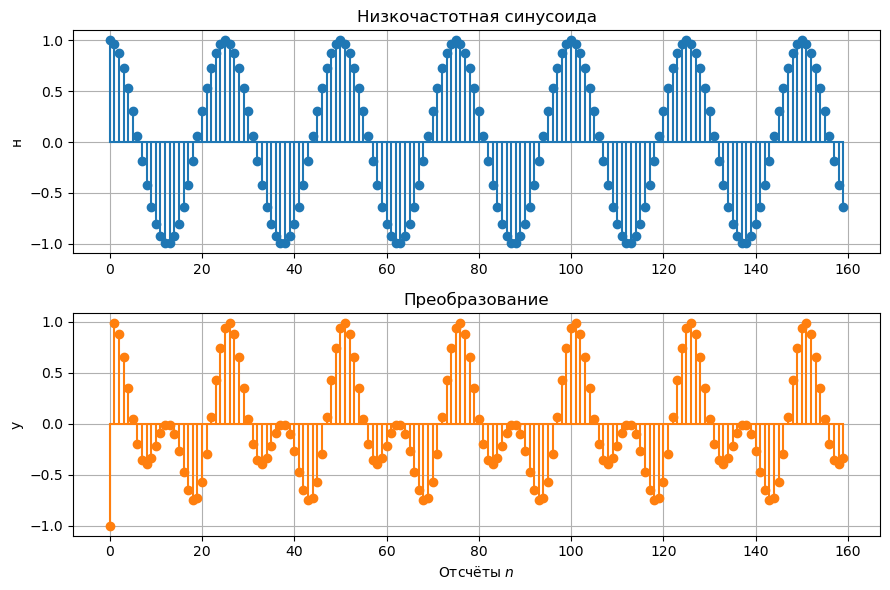

[график сохранён: /home/stanislau/University/TnAofDSP/lab3/source/low_freq_sin.png]


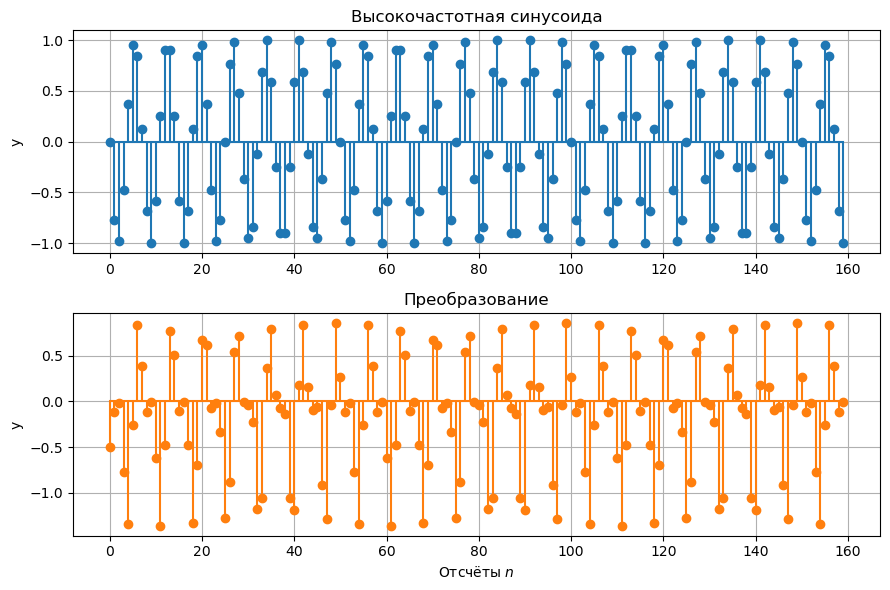

[график сохранён: /home/stanislau/University/TnAofDSP/lab3/source/high_freq_sin.png]


In [17]:
fig, (og, trans) = plt.subplots(2, 1, figsize=(9, 6))

og.stem(N, X3, basefmt="C0-")
og.set_ylabel("н")
og.set_title("Низкочастотная синусоида")

trans.stem(N, Y3, basefmt="C1-", linefmt="C1-", markerfmt="C1o")
trans.set_xlabel("Отсчёты $n$")
trans.set_ylabel("y")
trans.set_title("Преобразование")

plt.tight_layout()
save_and_show(fig, name="low_freq_sin")

fig, (og, trans) = plt.subplots(2, 1, figsize=(9, 6))

og.stem(N, X4, basefmt="C0-")
og.set_ylabel("y")
og.set_title("Высокочастотная синусоида")

trans.stem(N, Y4, basefmt="C1-", linefmt="C1-", markerfmt="C1o")
trans.set_xlabel("Отсчёты $n$")
trans.set_ylabel("y")
trans.set_title("Преобразование")

plt.tight_layout()
save_and_show(fig, name="high_freq_sin")



## 3.2-3.3. От блок-схемы к уравнению.

На рис. 16a–16h приведены блок-схемы дискретных
систем.
    
1. По блок-схеме своего варианта запишите разностное уравнение.
    
2. Реализуйте систему в MATLAB непосредственно по схеме – циклом с явным моделированием памяти, по одной переменной на каждый блок задержки z−1.
    
3. Постройте 40 отсчетов импульсной характеристики.

Для варианта 5 разностное уравнение имеет вид

$$ y(n)  = (x(n) + x(n-1)) - ( 0{,}3 y(n-2) - 0{,}3 y(n-4) )$$

Максимальная разность по модулю 0.0


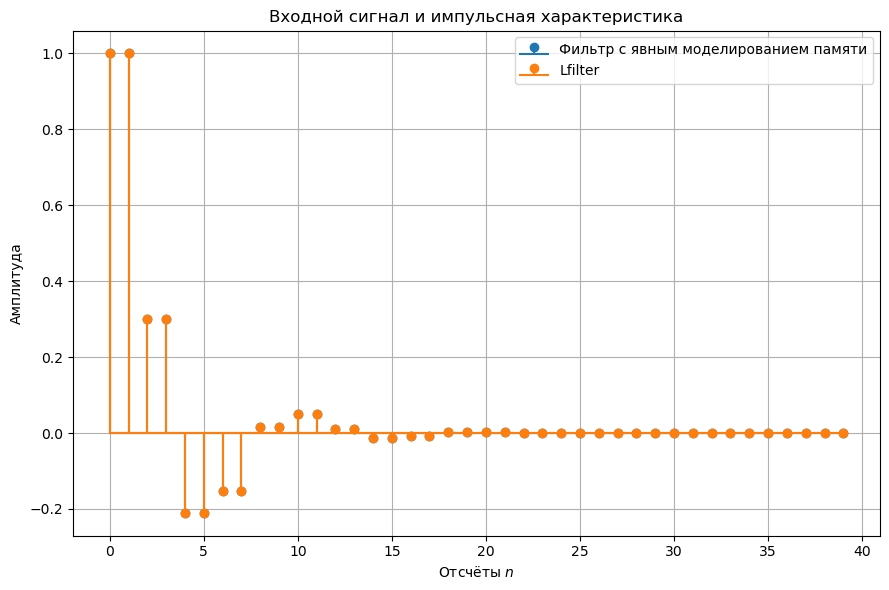

[график сохранён: /home/stanislau/University/TnAofDSP/lab3/source/3_2_filter.png]


In [18]:
N = np.arange(40)
X = np.zeros(len(N))
X[0] = 1.0

a = [1, 0, -0.3, 0, 0.3]
b = [1, 1, 0, 0, 0]

filter3_2 = IIRfilter(b, a)

Y1 = filter3_2.process_signal(X)

Y2 = sps.lfilter(b,a,X)


assert np.max(abs(Y1 - Y2)) < 1e-12, "False answer"
print("Максимальная разность по модулю", np.max(abs(Y1 - Y2)))

fig, ax = plt.subplots(figsize=(9, 6))
plt.stem(N, Y1, basefmt="C0-", linefmt="C0-", markerfmt="C0o", label="Фильтр с явным моделированием памяти")
plt.stem(N, Y2, basefmt="C1-", linefmt="C1-", markerfmt="C1o", label="Lfilter")
plt.xlabel("Отсчёты $n$")
plt.ylabel("Амплитуда")
plt.title("Входной сигнал и импульсная характеристика")
plt.legend()
plt.tight_layout()
save_and_show(fig, name="3_2_filter")

## 3.4. Частотная характеристика.

Вычислите КЧХ системы из задания 3.2 по её импульсной характеристике и постройте АЧХ и ФЧХ.
    
1. Сравните результат с freqz(b, a, 512). Удвойте длину усечённой импульсной характеристики и убедитесь, что график перестал меняться.
    
2. Найдите частоту ω0, на которой АЧХ минимальна, и укажите значение |H(ejω0 )|.
    
3. Сгенерируйте сигнал x(n) = ejω0n, n = 0, 1, . . . , N − 1, и пропустите его через систему. Постройте на одном рисунке вход и выход (вещественные части). Объясните
полученный результат.
    
4. При построении ФЧХ примените unwrap и объясните, что именно эта функция исправляет.

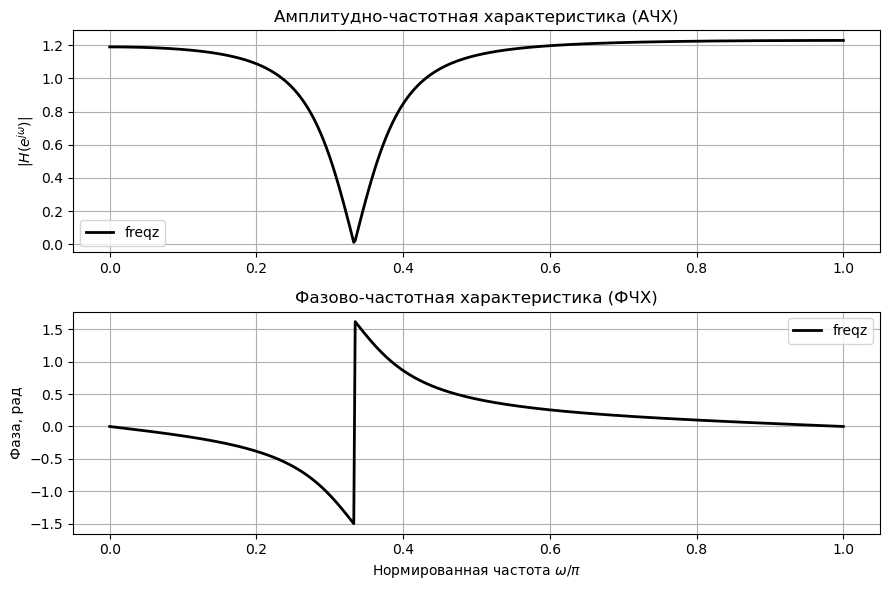

[график сохранён: /home/stanislau/University/TnAofDSP/lab3/source/afc_pfc_comparison.png]


In [21]:
w_notch = np.pi / 3
b = np.array([1.0, -2 * np.cos(w_notch), 1.0])
a = np.array([1.0, -0.8 * 2 * np.cos(w_notch), 0.64])

num_points = 512
w_grid = np.linspace(0, np.pi, num_points)

M1, M2 = 64, 128
delta1, delta2 = np.zeros(M1), np.zeros(M2)
delta1[0], delta2[0] = 1.0, 1.0

h_64 = sps.lfilter(b, a, delta1)
h_128 = sps.lfilter(b, a, delta2)

H_64 = get_CFR(h_64, num_points)
H_128 = get_CFR(h_128, num_points)
_, H_freqz = sps.freqz(b, a, worN=w_grid)

fig, (og, trans) = plt.subplots(2, 1, figsize=(9, 6))

og.plot(w_grid / np.pi, np.abs(H_freqz), 'k-', linewidth=2, label='freqz')
og.set_ylabel(r"$|H(e^{j\omega})|$")
og.set_title("Амплитудно-частотная характеристика (АЧХ)")
og.grid(True)
og.legend()

trans.plot(w_grid / np.pi, np.unwrap(np.angle(H_freqz)), 'k-', linewidth=2, label='freqz')
trans.set_xlabel(r"Нормированная частота $\omega / \pi$")
trans.set_ylabel(r"Фаза, рад")
trans.set_title("Фазово-частотная характеристика (ФЧХ)")
trans.grid(True)
trans.legend()

plt.tight_layout()
save_and_show(fig, name="afc_pfc_comparison")

In [24]:
print(np.min(H_freqz))

(-0.001029284869837972+0.02269668633790176j)


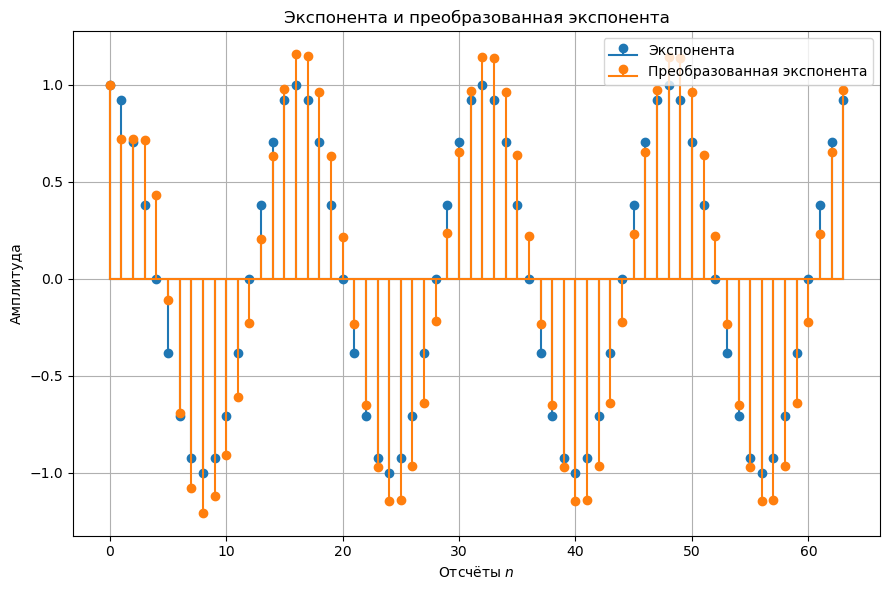

[график сохранён: /home/stanislau/University/TnAofDSP/lab3/source/4_3_filter.png]


In [43]:
N = np.arange(64)
exponent = np.exp(-1j * np.pi/8 * N)
exponent_transform = sps.lfilter(b, a, exponent)

fig, ax = plt.subplots(figsize=(9, 6))
plt.stem(N, exponent.real, basefmt="C0-", linefmt="C0-", markerfmt="C0o", label="Экспонента")
plt.stem(N, exponent_transform.real, basefmt="C1-", linefmt="C1-", markerfmt="C1o", label="Преобразованная экспонента")
plt.xlabel("Отсчёты $n$")
plt.ylabel("Амплитуда")
plt.title("Экспонента и преобразованная экспонента")
plt.legend()
plt.tight_layout()
save_and_show(fig, name="4_3_filter")